# Optimisation des performances de l'API de scoring

Ce notebook est le **rapport de l'étape 4** du projet. L'analyse de monitoring (notebook 02) a montré que l'API était trop lente sous charge : une latence p95 de 4 à 5 s, pour un objectif de 1 s. Ce rapport :

1. **identifie le goulot d'étranglement** par des mesures et du profilage ;
2. **présente les optimisations testées**, y compris celle qui n'a pas marché ;
3. **vérifie l'absence de régression** : le modèle doit donner exactement les mêmes scores ;
4. **démontre le gain sur l'API déployée**, à partir des données de production stockées dans Neon ;
5. **optimise l'image Docker** et mesure l'effet du processeur alloué au conteneur ;
6. **justifie la configuration finale** et liste les pistes restantes.

**Le modèle lui-même n'est pas modifié** : `model.pkl` est celui du Projet 6, comme demandé. Seul le code qui l'exécute a changé.

### En résumé

| | Avant | Après |
|---|---|---|
| Prédiction d'un client, en local | environ 12 ms | **environ 2,7 ms** |
| Latence médiane sur Render, sous charge | 2,8 s | **0,29 s** |
| Latence p95 sur Render, sous charge | 4,4 s | **0,61 s** (objectif : moins de 1 s) |
| Débit sur Render | 1,6 appel/s | **5,6 appels/s** |
| Image Docker (décompressée / à télécharger) | 796 Mo / 172 Mo | **651 Mo / 144 Mo** |
| Démarrage du conteneur à 0,5 CPU | 2,5 s | **2,0 s** |
| Scores | | **identiques**, sur 356 251 clients en local et 972 en production |

### Vocabulaire

- **Latence** : temps entre l'arrivée d'une requête et l'envoi de sa réponse.
- **Médiane** : la moitié des requêtes est plus rapide que cette valeur.
- **p95** (95e percentile) : 95 % des requêtes sont plus rapides que cette valeur. Elle décrit les requêtes lentes, celles que les utilisateurs remarquent.
- **Débit** : nombre de requêtes traitées par seconde.
- **Goulot d'étranglement** : l'étape la plus lente, celle qui limite tout le reste. Optimiser une autre étape ne sert presque à rien.
- **Fil (thread)** : une suite d'instructions exécutée par le processeur. Un programme peut lancer plusieurs fils pour calculer en parallèle sur plusieurs cœurs.
- **Quota de CPU** : la part de processeur accordée à un conteneur. Avec 0,1 CPU, Linux lui accorde 10 ms de calcul toutes les 100 ms, puis le met en pause jusqu'à la période suivante.
- **Profilage** : mesure du temps passé dans chaque fonction du code. On utilise `cProfile`, l'outil intégré à Python.

In [1]:
import cProfile
import inspect
import json
import pstats
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import load_dotenv

# Racine du projet (le notebook est dans notebooks/), pour importer src/ et scripts/, et lire data/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

# Adresse de la base de production, lue dans .env. À faire AVANT d'importer src.database,
# qui crée la connexion au moment de l'import.
load_dotenv(ROOT / ".env")

from scripts.mesure_inference import chronometrer  # noqa: E402
from scripts.simulation_trafic import charger_clients  # noqa: E402
from src.database import DATABASE_URL, engine  # noqa: E402
from src.predict import get_features, imputer_rapide, load_model, predict  # noqa: E402

assert DATABASE_URL.startswith("postgresql"), "DATABASE_URL absente : créer le fichier .env (voir README)"

# Avertissement connu et sans effet de HomeCreditImputer (pandas figé en 2.2.3), comme dans pytest.ini
warnings.filterwarnings("ignore", message="The behavior of DataFrame.idxmax")

In [2]:
# Une couleur par version du code, identique dans tous les graphiques
COULEURS = {"Avant": "#2a78d6", "Après": "#eb6834", "Essai 1": "#1baf7a"}
ENCRE, ENCRE_SECONDAIRE, ENCRE_DISCRETE, FOND = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"

# Style des graphiques : traits fins, grille discrète, pas de cadre inutile (comme le notebook 02)
plt.rcParams.update({
    "figure.figsize": (10, 4), "figure.dpi": 110,
    "figure.facecolor": FOND, "axes.facecolor": FOND,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.linewidth": 0.8,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": ENCRE_DISCRETE, "ytick.color": ENCRE_DISCRETE,
    "axes.labelcolor": ENCRE_SECONDAIRE, "text.color": ENCRE,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "lines.linewidth": 2,
})


def fr(valeur, decimales=1):
    """Nombre au format français (virgule décimale)."""
    return f"{valeur:.{decimales}f}".replace(".", ",")


def etiquette(ax, x, y, texte):
    """Valeur écrite au bout d'une barre horizontale."""
    ax.annotate(texte, (x, y), xytext=(4, 0), textcoords="offset points", va="center",
                fontsize=9, color=ENCRE_SECONDAIRE)


def ligne_de_seuil(ax, valeur, texte, hauteur=1.0, a_gauche=False):
    """Trace un seuil vertical (trait pointillé) avec son libellé, à droite ou à gauche du trait."""
    ax.axvline(valeur, color=ENCRE_SECONDAIRE, linestyle="--", linewidth=1)
    ax.annotate(texte, (valeur, hauteur), xycoords=("data", "axes fraction"), xytext=(-4 if a_gauche else 4, -12),
                textcoords="offset points", fontsize=9, color=ENCRE_SECONDAIRE, ha="right" if a_gauche else "left")


def resume(durees):
    """Médiane et p95 d'une liste de durées en millisecondes."""
    return {"médiane (ms)": np.median(durees), "p95 (ms)": np.percentile(durees, 95)}

## 1. Où passe le temps ? Mesure en local

Sur Render, la latence mélange plusieurs choses : le calcul, l'attente de son tour quand plusieurs requêtes arrivent en même temps, et le réseau. Pour isoler le **calcul**, on mesure d'abord sur le Mac, **sans API ni réseau**.

**Protocole** :
- 1 000 clients du jeu de test Kaggle, jamais vus par le modèle ;
- envoyés **un par un**, comme dans l'API, qui reçoit un client par requête ;
- 20 prédictions d'échauffement, non comptées, car les premiers appels sont plus lents.

Une prédiction passe par **trois étapes** :
1. **Préparation** : les données du client sont rangées dans un tableau pandas de 215 colonnes, dans l'ordre attendu par le modèle.
2. **Imputation** : les valeurs manquantes sont remplacées, selon les 3 règles définies au Projet 6. C'est la première étape du pipeline du modèle (`HomeCreditImputer`).
3. **LightGBM** : le modèle calcule la probabilité de défaut à partir de ses 200 arbres de décision.

In [3]:
model = load_model()
FEATURES = get_features(model)  # les 215 variables du modèle, dans l'ordre de l'entraînement
imputer, clf = model.named_steps["imputer"], model.named_steps["clf"]

# Tous les clients du Projet 6 (entraînement + test Kaggle), dont 1 000 clients de test pour les mesures
tous = charger_clients()
test = tous[tous["TARGET"].isna()].drop(columns="TARGET").sample(1000, random_state=42)
# Format reçu par predict() dans l'API : les 215 variables, None pour une valeur manquante
clients = [{k: (None if pd.isna(v) else float(v)) for k, v in ligne.items()} for ligne in test.to_dict("records")]


def tableau(client):
    """Étape 1 : le client sous forme de tableau pandas à 215 colonnes (comme dans predict())."""
    return pd.DataFrame([client]).reindex(columns=FEATURES).astype(float)


# Échauffement : les premiers appels sont plus lents (chargement en mémoire), on ne les compte pas
for client in clients[:20]:
    model.predict_proba(tableau(client))
    predict(model, [client])

print(f"{len(tous)} clients chargés, {len(clients)} clients de test pour les mesures")

356251 clients chargés, 1000 clients de test pour les mesures


In [4]:
# Version d'origine : le pipeline du Projet 6 tel quel (model.predict_proba)
t_total_avant = chronometrer(lambda c: model.predict_proba(tableau(c)), clients)

# Les trois étapes, chronométrées séparément sur les mêmes clients
tableaux = []
t_preparation = chronometrer(lambda c: tableaux.append(tableau(c)), clients)
imputes_origine = []
t_imputation_avant = chronometrer(lambda X: imputes_origine.append(imputer.transform(X)), tableaux)
t_lightgbm_avant = chronometrer(clf.predict_proba, imputes_origine)

ETAPES = ["1. Préparation", "2. Imputation", "3. LightGBM"]
etapes_avant = pd.DataFrame([resume(t) for t in (t_preparation, t_imputation_avant, t_lightgbm_avant)], index=ETAPES)
etapes_avant["part du temps (%)"] = etapes_avant["médiane (ms)"] / etapes_avant["médiane (ms)"].sum() * 100

print(f"Prédiction complète, version d'origine : {resume(t_total_avant)['médiane (ms)']:.1f} ms (médiane), "
      f"{resume(t_total_avant)['p95 (ms)']:.1f} ms (p95)")
etapes_avant.round(1)

Prédiction complète, version d'origine : 12.1 ms (médiane), 13.7 ms (p95)


,médiane (ms),p95 (ms),part du temps (%)
1. Préparation,1.1,1.3,9.4
2. Imputation,9.6,10.9,79.9
3. LightGBM,1.3,1.4,10.7


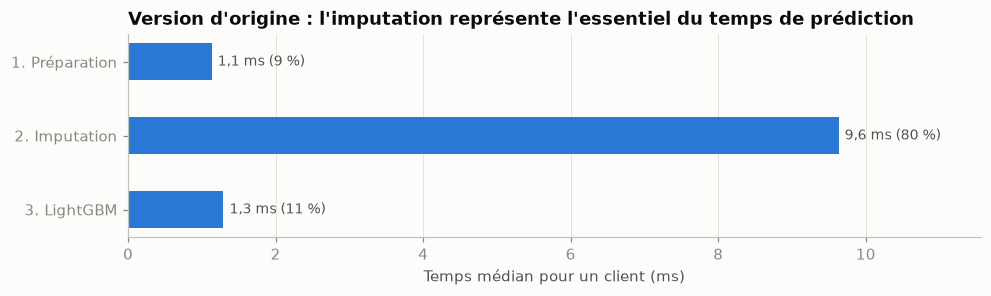

In [5]:
fig, ax = plt.subplots(figsize=(10, 2.4))
valeurs = etapes_avant["médiane (ms)"][::-1]
ax.barh(valeurs.index, valeurs, height=0.5, color=COULEURS["Avant"])
for y, (v, part) in enumerate(zip(valeurs, etapes_avant["part du temps (%)"][::-1])):
    etiquette(ax, v, y, f"{fr(v)} ms ({part:.0f} %)")
ax.set_xlabel("Temps médian pour un client (ms)")
ax.set_title("Version d'origine : l'imputation représente l'essentiel du temps de prédiction")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, valeurs.max() * 1.2)
plt.show()

### Profilage : quelles fonctions coûtent le plus ?

`cProfile` enregistre chaque appel de fonction pendant 200 prédictions. Le tableau donne, **pour une prédiction** :
- le nombre d'appels de chaque fonction ;
- son temps cumulé, c'est-à-dire avec les fonctions qu'elle appelle elle-même.

Le profilage ralentit l'exécution, il faut donc regarder **les proportions et les nombres d'appels**, pas les temps absolus.

Le code de l'imputation vient du notebook du Projet 6. Il a été enregistré avec le modèle, ce qui explique son nom de fichier numéroté (par exemple `745137067.py`).

In [6]:
def profiler(fonction, elements):
    """Exécute fonction(element) pour chaque élément sous cProfile et renvoie les statistiques."""
    profil = cProfile.Profile()
    profil.enable()
    for element in elements:
        fonction(element)
    profil.disable()
    return pstats.Stats(profil).stats


def top_fonctions(stats, nb_predictions, nb=12):
    """Les fonctions les plus coûteuses, avec leur nombre d'appels et leur temps ramenés à une prédiction."""
    lignes = [
        {"fonction": f"{Path(fichier).name}:{nom}",
         "appels par prédiction": appels / nb_predictions,
         "temps cumulé par prédiction (ms)": cumule / nb_predictions * 1000}
        for (fichier, _, nom), (_, appels, _, cumule, _) in stats.items()
    ]
    return (pd.DataFrame(lignes).sort_values("temps cumulé par prédiction (ms)", ascending=False)
            .head(nb).round(2).reset_index(drop=True))


def appels_par_prediction(stats, nom_fonction, nb_predictions):
    """Nombre d'appels d'une fonction donnée, pour une prédiction."""
    return sum(appels for (_, _, nom), (_, appels, *_) in stats.items() if nom == nom_fonction) / nb_predictions


stats_avant = profiler(lambda c: model.predict_proba(tableau(c)), clients[:200])
top_fonctions(stats_avant, 200)

,fonction,appels par prédiction,temps cumulé par prédiction (ms)
0,3357619170.py:<lambda>,1.01,25.52
1,pipeline.py:predict_proba,1.00,22.61
2,_set_output.py:wrapped,1.00,20.49
3,745137067.py:transform,1.00,20.45
4,745137067.py:_apply_rules_1_2,1.00,13.57
5,frame.py:__setitem__,153.78,6.66
6,frame.py:_set_item,153.78,6.15
7,generic.py:fillna,165.57,6.01
8,frame.py:_set_item_mgr,153.78,5.07
9,frame.py:_iset_item_mgr,153.78,4.59


**Lecture.**

- **Une prédiction prend environ 12 ms en local, et l'imputation en représente 80 %.** LightGBM, c'est-à-dire le modèle lui-même, n'en représente qu'environ 10 %.
- **Le profilage montre pourquoi.** Pour un seul client, l'imputation fait environ **154 affectations de colonne** (`__setitem__`) et **166 remplissages de valeurs manquantes** (`fillna`). En effet, la règle 2 du Projet 6 traite les 143 colonnes d'historique externe **une par une**, dans une boucle.
- **Chaque opération pandas a un coût fixe** : vérifications, gestion de la mémoire du tableau. Ce coût est le même pour 1 ligne ou pour 1 000 lignes.
- **Conclusion : le goulot d'étranglement est le code de l'imputation, pas le modèle.** C'est ce qui guide l'optimisation. Convertir le modèle avec ONNX Runtime, la piste souvent citée, ne viserait que les 10 % du temps passés dans LightGBM.

## 2. Les essais d'optimisation

### L'hypothèse

Si le coût vient du **nombre d'opérations pandas**, et non de la quantité de données, alors traiter 1 000 clients en un seul appel ne doit pas coûter beaucoup plus cher que d'en traiter un seul. On le vérifie :

In [7]:
debut = time.perf_counter()
model.predict_proba(pd.DataFrame(clients).reindex(columns=FEATURES).astype(float))
par_lot_ms = (time.perf_counter() - debut) * 1000

print(f"1 000 clients en un seul appel : {par_lot_ms:.0f} ms, soit {par_lot_ms / 1000:.3f} ms par client")
print(f"1 client par appel            : {np.median(t_total_avant):.1f} ms par client, "
      f"{np.median(t_total_avant) / (par_lot_ms / 1000):.0f} fois plus par client")

1 000 clients en un seul appel : 36 ms, soit 0.036 ms par client
1 client par appel            : 12.1 ms par client, 333 fois plus par client


**L'hypothèse est confirmée.** Le coût d'une prédiction est presque entièrement un **coût fixe par appel**, qu'il y ait 1 ou 1 000 clients. Or l'API reçoit un client par requête : elle paie ce coût fixe à chaque fois.

L'objectif est donc de **réduire le nombre d'opérations par appel**, sans changer les règles d'imputation ni les valeurs apprises au Projet 6.

### Essai 1 : pandas, une opération par règle au lieu d'une par colonne

Première idée : garder pandas, mais traiter les 143 colonnes de la règle 2 et les 31 colonnes de la règle 3 en une seule instruction chacune, au lieu d'une boucle sur les colonnes.

In [8]:
def imputer_pandas_par_groupes(imputer, X):
    """Essai 1 : même imputation que le Projet 6, en pandas, avec une instruction par règle."""
    X = X.replace([np.inf, -np.inf], np.nan)
    # Règle 1 : âge de la voiture
    sans_voiture = X["FLAG_OWN_CAR"] == 0
    X.loc[sans_voiture, "OWN_CAR_AGE"] = X.loc[sans_voiture, "OWN_CAR_AGE"].fillna(0)
    X["OWN_CAR_AGE"] = X["OWN_CAR_AGE"].fillna(imputer.own_car_age_median_)
    # Règle 2 : les 143 colonnes d'historique externe en une instruction
    X[imputer.external_cols_] = X[imputer.external_cols_].fillna(0)
    # Règle 3 : les 31 colonnes restantes en une instruction (médiane du groupe, sinon médiane globale)
    groupe = imputer._group_key(X)
    medianes = imputer.group_medians_.reindex(groupe.values).fillna(imputer.global_medians_)
    medianes.index = X.index
    X[imputer.remaining_cols_] = X[imputer.remaining_cols_].fillna(medianes)
    return X.fillna(0)


# Même résultat que l'original ?
for X in tableaux[:50]:
    pd.testing.assert_frame_equal(imputer_pandas_par_groupes(imputer, X), imputer.transform(X))

t_imputation_essai_1 = chronometrer(lambda X: imputer_pandas_par_groupes(imputer, X), tableaux)
stats_essai_1 = profiler(lambda X: imputer_pandas_par_groupes(imputer, X), tableaux[:200])
print(f"Imputation, essai 1 : {np.median(t_imputation_essai_1):.2f} ms (médiane), "
      f"contre {np.median(t_imputation_avant):.2f} ms pour l'original")

Imputation, essai 1 : 8.44 ms (médiane), contre 9.63 ms pour l'original


**Lecture.**

- **L'essai 1 ne fait presque rien gagner** : l'imputation n'est qu'environ 1,1 fois plus rapide.
- **Le profilage explique pourquoi.** Le nombre d'affectations de colonne **augmente** : 206 par client, contre 154 dans le code d'origine (voir le tableau plus bas). Quand on écrit `X[143 colonnes] = ...`, pandas reboucle en interne sur chaque colonne.
- **Le coût ne vient donc pas de notre boucle**, mais de la façon dont pandas range et modifie les colonnes d'un tableau.
- **Conclusion : pour aller plus vite, il faut faire le calcul en dehors de pandas.** C'est un essai « raté », mais il a permis de comprendre la vraie cause.

### Essai 2 : numpy (version retenue)

Deuxième idée : faire l'imputation sur une **matrice numpy**, c'est-à-dire un simple bloc de nombres en mémoire, sans la gestion des colonnes de pandas. Les trois règles deviennent des opérations sur des masques, comme « toutes les cases vides de ces 143 colonnes ». Le tableau pandas n'est reconstruit **qu'une seule fois**, à la fin.

Les valeurs utilisées (médiane des propriétaires de voiture, médianes par groupe de profil, médianes globales) sont **lues directement dans l'imputer du modèle chargé** : ce sont celles apprises au Projet 6.

Cette version est celle de l'API, dans `src/predict.py` :

In [9]:
print(inspect.getsource(imputer_rapide))

def imputer_rapide(imputer, X):
    """
    Même imputation que HomeCreditImputer.transform() (Projet 6), mais calculée sur une matrice numpy.
    Le code d'origine modifie le tableau pandas colonne par colonne (environ 150 opérations par client,
    chacune avec un coût fixe) : c'était 80 % du temps d'inférence (mesuré avec scripts/mesure_inference.py).
    Les valeurs utilisées (médianes) sont celles apprises au Projet 6 : imputer = étape du modèle chargé.
    """
    colonnes = X.columns
    valeurs = X.to_numpy(dtype=float, copy=True)
    # Les ratios peuvent valoir +/-inf (division par 0) : traités comme des valeurs manquantes
    valeurs[np.isinf(valeurs)] = np.nan

    # Règle 1 : pas de voiture -> âge de la voiture = 0, sinon médiane des propriétaires
    age = colonnes.get_loc("OWN_CAR_AGE")
    sans_voiture = valeurs[:, colonnes.get_loc("FLAG_OWN_CAR")] == 0
    valeurs[sans_voiture & np.isnan(valeurs[:, age]), age] = 0
    valeurs[np.isnan(valeurs[:, age]), age] = imputer.ow

In [10]:
imputes_rapide = []
t_imputation_apres = chronometrer(lambda X: imputes_rapide.append(imputer_rapide(imputer, X)), tableaux)
t_lightgbm_apres = chronometrer(clf.predict_proba, imputes_rapide)
t_total_apres = chronometrer(lambda c: predict(model, [c]), clients)  # predict() de l'API, version optimisée
stats_essai_2 = profiler(lambda X: imputer_rapide(imputer, X), tableaux[:200])

# Comparaison des trois versions de l'imputation
imputation = pd.DataFrame(
    [resume(t) for t in (t_imputation_avant, t_imputation_essai_1, t_imputation_apres)],
    index=["Code d'origine (Projet 6)", "Essai 1 : pandas, par groupes", "Essai 2 : numpy (retenu)"],
)
imputation["fois plus rapide"] = imputation["médiane (ms)"].iloc[0] / imputation["médiane (ms)"]
imputation["affectations de colonne par client"] = [
    appels_par_prediction(s, "_set_item", 200) for s in (stats_avant, stats_essai_1, stats_essai_2)
]
imputation.round(2)

,médiane (ms),p95 (ms),fois plus rapide,affectations de colonne par client
Code d'origine (Projet 6),9.63,10.94,1.00,153.78
"Essai 1 : pandas, par groupes",8.44,8.72,1.14,206.00
Essai 2 : numpy (retenu),0.76,0.84,12.67,0.00


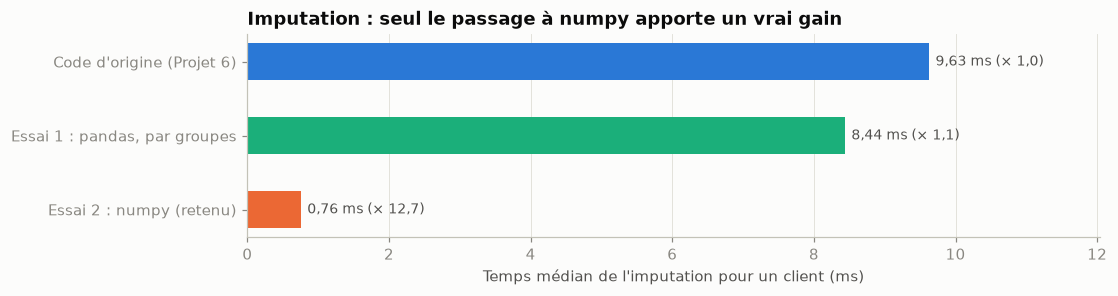

In [11]:
fig, ax = plt.subplots(figsize=(10, 2.4))
couleurs = [COULEURS["Avant"], COULEURS["Essai 1"], COULEURS["Après"]]
valeurs = imputation["médiane (ms)"][::-1]
ax.barh(valeurs.index, valeurs, height=0.5, color=couleurs[::-1])
for y, (v, gain) in enumerate(zip(valeurs, imputation["fois plus rapide"][::-1])):
    etiquette(ax, v, y, f"{fr(v, 2)} ms (× {fr(gain)})")
ax.set_xlabel("Temps médian de l'imputation pour un client (ms)")
ax.set_title("Imputation : seul le passage à numpy apporte un vrai gain")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, valeurs.max() * 1.25)
plt.show()

### Effet sur la prédiction complète

In [12]:
etapes_apres = pd.DataFrame([resume(t) for t in (t_preparation, t_imputation_apres, t_lightgbm_apres)], index=ETAPES)
avant_apres = pd.DataFrame({
    "avant, médiane (ms)": list(etapes_avant["médiane (ms)"]) + [np.median(t_total_avant)],
    "après, médiane (ms)": list(etapes_apres["médiane (ms)"]) + [np.median(t_total_apres)],
}, index=ETAPES + ["Prédiction complète"])
avant_apres["fois plus rapide"] = avant_apres["avant, médiane (ms)"] / avant_apres["après, médiane (ms)"]
avant_apres["part du temps après (%)"] = list(etapes_apres["médiane (ms)"] / etapes_apres["médiane (ms)"].sum() * 100) + [100]
avant_apres.round(2)

,"avant, médiane (ms)","après, médiane (ms)",fois plus rapide,part du temps après (%)
1. Préparation,1.13,1.13,1.00,45.38
2. Imputation,9.63,0.76,12.67,30.47
3. LightGBM,1.29,0.60,2.14,24.15
Prédiction complète,12.08,2.75,4.40,100.00


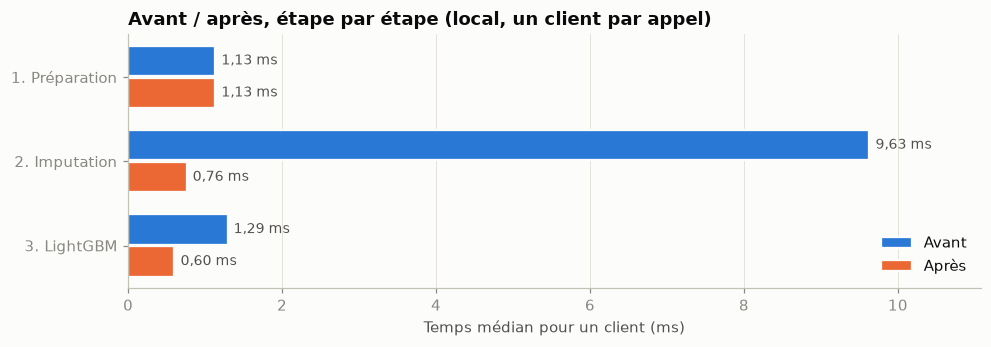

In [13]:
fig, ax = plt.subplots(figsize=(10, 3))
positions = np.arange(len(ETAPES))[::-1]
for decalage, (nom, colonne) in zip((0.19, -0.19), [("Avant", "avant, médiane (ms)"), ("Après", "après, médiane (ms)")]):
    valeurs = avant_apres.loc[ETAPES, colonne]
    ax.barh(positions + decalage, valeurs, height=0.36, color=COULEURS[nom], label=nom,
            edgecolor=FOND, linewidth=1.5)
    for y, v in zip(positions + decalage, valeurs):
        etiquette(ax, v, y, f"{fr(v, 2)} ms")
ax.set_yticks(positions, ETAPES)
ax.set_xlabel("Temps médian pour un client (ms)")
ax.set_title("Avant / après, étape par étape (local, un client par appel)")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, avant_apres.loc[ETAPES, "avant, médiane (ms)"].max() * 1.15)
ax.legend(loc="lower right")
plt.show()

**Lecture.**

- **Avec numpy, l'imputation passe d'environ 9,3 ms à environ 0,7 ms, soit environ 13 fois plus vite.** Il n'y a plus aucune affectation de colonne pandas.
- **La prédiction complète passe d'environ 12 ms à environ 2,7 ms, soit plus de 4 fois plus vite.**
- **LightGBM accélère aussi (environ 1,2 → 0,6 ms) sans qu'on l'ait touché.**
  - Il reçoit maintenant un tableau rangé en **un seul bloc de nombres**, qu'il convertit plus vite dans son format interne.
  - Avant, le tableau sortait de pandas en morceaux, après environ 150 modifications de colonnes.
- **Le goulot d'étranglement s'est déplacé** : la préparation du tableau (environ 1,1 ms, inchangée) représente maintenant près de la moitié du temps. C'est la prochaine piste (partie 6).

## 3. Non-régression : le modèle donne-t-il exactement les mêmes résultats ?

Une optimisation n'est acceptable que si elle ne change pas les prédictions. On compare l'imputation d'origine et l'imputation numpy sur **tous les clients du Projet 6** : les 307 511 clients d'entraînement et les 48 744 du test Kaggle.

On vérifie deux choses :
- les **tableaux imputés** doivent être identiques à la dernière décimale (`assert_frame_equal`) ;
- les **scores** doivent être identiques.

Le calcul est fait par paquets de 50 000 clients pour limiter la mémoire. Le traitement par lot est rapide (voir partie 2) : la vérification ne prend que quelques secondes.

In [14]:
X_tous = tous[FEATURES].astype(float)
ecart_max = 0.0
for i in range(0, len(X_tous), 50_000):
    X = X_tous.iloc[i:i + 50_000]
    impute = imputer_rapide(imputer, X)
    pd.testing.assert_frame_equal(impute, imputer.transform(X))  # lève une erreur à la moindre différence
    ecart = np.abs(clf.predict_proba(impute)[:, 1] - model.predict_proba(X)[:, 1]).max()
    ecart_max = max(ecart_max, ecart)

print(f"{len(X_tous)} clients : tableaux imputés identiques, écart maximal entre les scores = {ecart_max}")

356251 clients : tableaux imputés identiques, écart maximal entre les scores = 0.0


**Aucune régression** : les données imputées et les scores sont strictement identiques pour les 356 251 clients.

Pour que cela reste vrai, un **test automatique** (`tests/test_predict.py`) compare les deux imputations à chaque push, dans la CI. Il porte sur 6 cas particuliers : pas de voiture, valeur infinie, profil de revenu différent, client presque vide… La CI n'a pas les données Kaggle, d'où ces cas construits à la main.

## 4. Le gain sur l'API déployée (Render)

La version optimisée a été déployée automatiquement par le pipeline CI/CD (commit `2fb5352`). Pour mesurer le gain réel, on a renvoyé à l'API **les mêmes clients, dans les mêmes conditions** que lors de la simulation de production du 29/10 :
- les **1 000 premiers clients** de la vague normale : le tirage aléatoire utilise la même graine, il donne donc les mêmes clients dans le même ordre ;
- **8 requêtes en parallèle**, comme avant ;
- la même offre gratuite de Render : 0,1 CPU et 512 Mo de mémoire.

Commande utilisée :

```bash
python scripts/simulation_trafic.py --normaux 1000 --derives 0 --taux-erreur 0 --bilan data/mesure_render_2fb5352.json
```

Chaque appel est enregistré dans Neon avec la **version du code** qui l'a traité. On distingue ainsi l'avant (`7a8c3f1`) et l'après (`2fb5352`). Pour comparer les mêmes clients, on rapproche les appels des deux versions par leurs données d'entrée, qui sont identiques.

In [15]:
VERSION_AVANT, VERSION_APRES = "7a8c3f1", "2fb5352"

appels = pd.read_sql("SELECT * FROM predictions WHERE statut_http = 200 ORDER BY date_appel", engine)
# Clé de rapprochement : les données d'entrée du client, écrites de façon canonique (clés triées)
appels["cle"] = appels["entrees"].apply(lambda e: json.dumps(e, sort_keys=True))

apres = appels[appels["version"] == VERSION_APRES]
paires = appels[appels["version"] == VERSION_AVANT].merge(apres, on="cle", suffixes=("_avant", "_apres"))
# Avant : uniquement les clients aussi envoyés après
avant = appels[(appels["version"] == VERSION_AVANT) & appels["cle"].isin(paires["cle"])]

print(f"Appels réussis en base : {appels['version'].value_counts().to_dict()}")
print(f"{len(paires)} clients traités avec succès par les deux versions")
print("Non-régression en production : scores identiques =",
      (paires["probabilite_defaut_avant"] == paires["probabilite_defaut_apres"]).all(),
      "| décisions identiques =", (paires["decision_avant"] == paires["decision_apres"]).all())

Appels réussis en base : {'7a8c3f1': 2938, '2fb5352': 993}
972 clients traités avec succès par les deux versions
Non-régression en production : scores identiques = True | décisions identiques = True


In [16]:
def debit(df):
    """Appels traités par seconde, entre le premier et le dernier appel."""
    return len(df) / (df["date_appel"].max() - df["date_appel"].min()).total_seconds()


# Durée médiane vue par le client (réseau compris), notée par le script de simulation
with open(ROOT / "data" / "simulation_vagues.json") as f:
    client_avant = json.load(f)[0]["duree_mediane_client_s"] * 1000  # médiane de toute la vague normale (2 000 clients)
with open(ROOT / "data" / f"mesure_render_{VERSION_APRES}.json") as f:
    client_apres = json.load(f)[0]["duree_mediane_client_s"] * 1000


def mesures(df, duree_client_ms):
    return {
        "Temps du modèle, médiane (ms)": df["inference_ms"].median(),
        "Temps du modèle, p95 (ms)": df["inference_ms"].quantile(0.95),
        "Latence serveur, médiane (ms)": df["latence_ms"].median(),
        "Latence serveur, p95 (ms)": df["latence_ms"].quantile(0.95),
        "Hors modèle, médiane (ms)": (df["latence_ms"] - df["inference_ms"]).median(),
        "Débit (appels/s)": debit(df),
        "Durée vue par le client, médiane (ms)": duree_client_ms,
    }


render = pd.DataFrame({f"Avant ({VERSION_AVANT})": mesures(avant, client_avant),
                       f"Après ({VERSION_APRES})": mesures(apres, client_apres)})
render["gain (fois)"] = render.iloc[:, 0] / render.iloc[:, 1]
render.loc["Débit (appels/s)", "gain (fois)"] = 1 / render.loc["Débit (appels/s)", "gain (fois)"]  # plus = mieux
render.round(1)

,Avant (7a8c3f1),Après (2fb5352),gain (fois)
"Temps du modèle, médiane (ms)",2600.3,196.4,13.2
"Temps du modèle, p95 (ms)",4242.7,503.6,8.4
"Latence serveur, médiane (ms)",2796.0,287.2,9.7
"Latence serveur, p95 (ms)",4405.0,606.4,7.3
"Hors modèle, médiane (ms)",107.0,40.7,2.6
Débit (appels/s),1.6,5.6,3.4
"Durée vue par le client, médiane (ms)",4780.0,1100.0,4.3


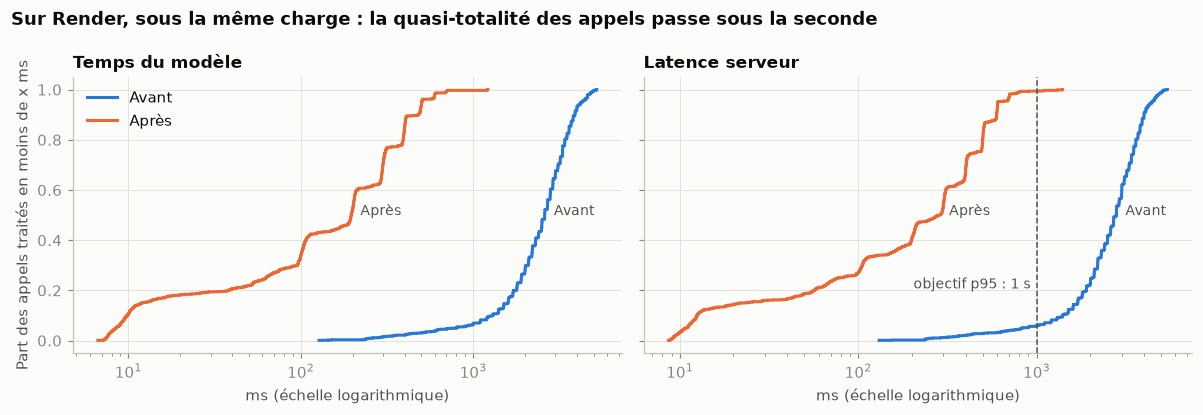

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, colonne, titre in zip(axes, ["inference_ms", "latence_ms"], ["Temps du modèle", "Latence serveur"]):
    for nom, df in [("Avant", avant), ("Après", apres)]:
        valeurs = np.sort(df[colonne].to_numpy())
        part = np.arange(1, len(valeurs) + 1) / len(valeurs)
        ax.step(valeurs, part, where="post", color=COULEURS[nom], label=nom)
        # Libellé direct, à la hauteur de la médiane
        ax.annotate(nom, (np.median(valeurs), 0.5), xytext=(6, 0), textcoords="offset points",
                    fontsize=9, color=ENCRE_SECONDAIRE)
    ax.set_xscale("log")
    ax.set_title(titre, fontsize=11)
    ax.set_xlabel("ms (échelle logarithmique)")
ligne_de_seuil(axes[1], 1000, "objectif p95 : 1 s", hauteur=0.3, a_gauche=True)
axes[0].set_ylabel("Part des appels traités en moins de x ms")
axes[0].legend(loc="upper left")
fig.suptitle("Sur Render, sous la même charge : la quasi-totalité des appels passe sous la seconde",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

**Comment lire ce graphique.** Chaque courbe indique, pour une durée x, la part des appels traités en moins de x ms : plus une courbe est à gauche, plus l'API est rapide. Par exemple, la hauteur 0,95 correspond au p95. L'échelle horizontale est **logarithmique** : chaque graduation multiplie la durée par 10. Sans cela, les deux courbes, séparées d'un facteur 10, seraient illisibles sur le même graphique.

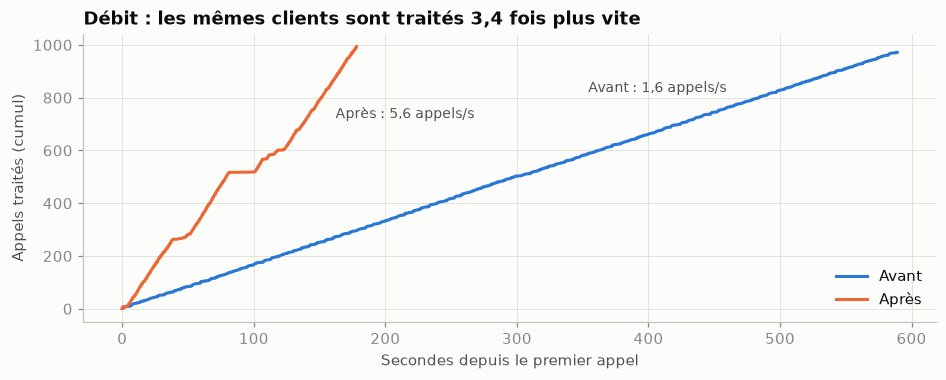

In [18]:
fig, ax = plt.subplots(figsize=(10, 3.4))
# Libellé direct à 80 % de chaque courbe : au-dessus à gauche pour "Avant", en dessous à droite pour "Après"
for nom, df, (dx, dy, cote) in [("Avant", avant, (-10, 10, "right")), ("Après", apres, (10, -10, "left"))]:
    secondes = (df["date_appel"] - df["date_appel"].min()).dt.total_seconds()
    ax.plot(secondes, np.arange(1, len(df) + 1), color=COULEURS[nom], label=nom)
    i = int(len(df) * 0.8)
    ax.annotate(f"{nom} : {fr(debit(df))} appels/s", (secondes.iloc[i], i + 1), xytext=(dx, dy),
                textcoords="offset points", ha=cote, va="center", fontsize=9, color=ENCRE_SECONDAIRE)
ax.set_xlabel("Secondes depuis le premier appel")
ax.set_ylabel("Appels traités (cumul)")
ax.set_title(f"Débit : les mêmes clients sont traités {fr(debit(apres) / debit(avant))} fois plus vite")
ax.legend(loc="lower right")
plt.show()

In [19]:
# Loi de Little : requêtes présentes en même temps dans le serveur = débit x latence
for nom, df in [("Avant", avant), ("Après", apres)]:
    en_cours = debit(df) * df["latence_ms"].mean() / 1000
    print(f"{nom:<6}: en moyenne {en_cours:.1f} requêtes en cours de traitement en même temps dans le serveur")

Avant : en moyenne 4.5 requêtes en cours de traitement en même temps dans le serveur
Après : en moyenne 1.6 requêtes en cours de traitement en même temps dans le serveur


**Lecture.**

**Sur les mêmes 972 clients et sous la même charge, le gain est net :**
- le temps du modèle (médiane) passe de **2,6 s à 0,2 s** ;
- la latence serveur p95 passe de **4,4 s à 0,61 s**, désormais **sous l'objectif d'une seconde** ;
- le débit passe de **1,6 à 5,6 appels par seconde** ;
- les scores et les décisions sont **identiques** : la non-régression est vérifiée en production.

**Pourquoi le gain sur Render (environ 13 fois sur le temps du modèle) dépasse-t-il le gain local (plus de 4 fois) ?**
- **0,1 CPU est un quota, pas un processeur lent.**
  - Le conteneur a droit à environ 10 ms de calcul toutes les 100 ms.
  - Quand il a consommé sa part, il est mis en pause jusqu'à la période suivante.
- **Les marches tous les 100 ms sur les courbes sont très probablement la signature de ce quota** : une requête attend 1, 2, 3… périodes avant d'être terminée.
- **Les appels les plus rapides donnent le vrai temps de calcul.**
  - Environ 15 % des appels de la version optimisée prennent environ 10 ms dans le modèle : ce sont ceux qui arrivent quand le quota est disponible.
  - C'est environ 3 fois le temps local, un écart normal entre un serveur partagé et un Mac récent.
- **Avant, 8 requêtes se partageaient ce quota et attendaient leur tour.**
  - La **loi de Little** (requêtes en cours = débit × latence) le montre : en moyenne 4,5 requêtes étaient en traitement en même temps dans le serveur, contre 1,6 après.
  - Avec moins de calcul par requête, la file d'attente se vide. L'attente diminue alors **beaucoup plus** que le calcul : c'est l'effet non linéaire des files d'attente.
- **Le temps « hors modèle » baisse aussi (107 → 41 ms)** pour la même raison : la validation des données et la mise en forme de la réponse attendaient elles aussi le processeur.

**Côté client, la durée médiane passe de 4,8 s à 1,1 s.** L'écart restant avec la latence serveur (environ 0,8 s) a deux causes :
- le réseau entre le Mac et Francfort, environ 0,6 s d'aller-retour, d'autant que le script ouvre une nouvelle connexion sécurisée à chaque requête ;
- l'écriture en base, faite avant l'envoi de la réponse (partie 6).

**Limites de la comparaison :**
- les deux mesures sont à 8 jours d'écart, sur une machine partagée ;
- la durée client « avant » est la médiane de toute la vague du 29/10 (2 000 appels) ;
- la courbe de débit montre une pause d'environ 20 s vers la 80e seconde : aucun appel n'est arrivé au serveur pendant ce temps, la cause se situe donc côté réseau ou côté Render ;
- 6 requêtes sont restées sans réponse et n'apparaissent pas en base.

## 5. L'image Docker et le choix du matériel

Les sections précédentes ont accéléré le **code**. Celle-ci regarde le **conteneur** : la taille de l'image, son démarrage et sa consommation, selon le processeur dont il dispose.

**Méthode.** Le script `scripts/mesure_docker.py` lance l'image en limitant ses ressources, comme le fait un hébergeur : `--cpus 0.1 --memory 512m` reproduit l'offre gratuite de Render. Pour chaque niveau de CPU, il mesure :
- le **démarrage**, du lancement du conteneur jusqu'à la première réponse de `/health` ;
- la **latence** de 40 requêtes envoyées une par une, lue dans les logs de l'API ;
- la **mémoire** et le nombre de **fils** du processus ;
- le **score** du client d'exemple, qui doit rester 0,361.

Les mesures sont faites en local, sur le Mac (Docker Desktop), sans base de données ni réseau : on isole le conteneur. Chaque configuration est mesurée 3 fois, car les résultats varient d'un essai à l'autre.

### Ce que contenait l'image

- **796 Mo** une fois décompressée (172 Mo à télécharger), dont 442 Mo de bibliothèques Python.
- **145 Mo de suites de tests**, livrées avec pandas, scipy, numpy et scikit-learn, et jamais utilisées en production.
- **31 fils de calcul** après la première prédiction :
  - 20 lancés dès le démarrage par **OpenBLAS**, la bibliothèque de calcul matriciel embarquée par numpy et par scipy (10 chacun) ;
  - 10 lancés par **OpenMP**, la bibliothèque de calcul parallèle utilisée par LightGBM, même si le modèle est réglé sur `n_jobs=1` ;
  - le conteneur voit les 11 cœurs du Mac, et chaque bibliothèque prévoit un fil par cœur, alors que Render ne donne qu'un dixième de cœur.

### Les deux optimisations

1. **Supprimer les suites de tests dans la même instruction que l'installation** : `RUN pip install ... && find ... -name tests -exec rm -rf`.
   - Une image Docker est un empilement de **couches** : chaque instruction du Dockerfile en ajoute une.
   - Si la suppression était faite dans une instruction suivante, les fichiers resteraient dans la couche de l'installation. Ils seraient seulement masqués, et l'image ne maigrirait pas.
2. **Un seul fil de calcul** : `ENV OPENBLAS_NUM_THREADS=1 OMP_NUM_THREADS=1`. L'API score un client à la fois : inutile de préparer des fils pour 11 cœurs.

In [20]:
def charger(nom):
    """Bilan JSON écrit par scripts/mesure_docker.py (dans data/, non versionné)."""
    return json.loads((ROOT / "data" / nom).read_text())


def medianes(bilan):
    """Médiane des essais, pour chaque niveau de CPU."""
    return pd.DataFrame(bilan["mesures"]).groupby("cpus").median(numeric_only=True)


# Image d'origine ("Avant") et image optimisée ("Après"), mesurées de la même façon
images = {"Avant": charger("mesure_docker_avant.json"), "Après": charger("mesure_docker_apres.json")}
# Même mesure sous charge : 8 clients simultanés, 160 requêtes, à 0,5 CPU
charge = {"Avant": charger("mesure_docker_avant_charge.json"), "Après": charger("mesure_docker_apres_charge.json")}

lignes = {}
for nom, bilan in images.items():
    m, c = medianes(bilan), medianes(charge[nom])
    lignes[nom] = {
        "Image décompressée": bilan["taille_decompressee"].replace("MB", " Mo"),
        "Image compressée (à télécharger)": f'{bilan["taille_compressee_mo"]} Mo',
        "Fils du processus de l'API": f'{m.loc[1.0, "fils"]:.0f}',
        "Mémoire utilisée": f'{m.loc[1.0, "ram_mo"]:.0f} Mo',
        "Démarrage à 1 CPU": f'{fr(m.loc[1.0, "demarrage_s"])} s',
        "Démarrage à 0,5 CPU": f'{fr(m.loc[0.5, "demarrage_s"])} s',
        "Démarrage à 0,1 CPU (Render gratuit)": f'{m.loc[0.1, "demarrage_s"]:.0f} s',
        "Inférence médiane à 0,5 CPU": f'{fr(m.loc[0.5, "inference_mediane_ms"])} ms',
        "Inférence médiane à 0,1 CPU": f'{m.loc[0.1, "inference_mediane_ms"]:.0f} ms',
        "Débit sous charge (8 clients, 0,5 CPU)": f'{c.loc[0.5, "debit_appels_s"]:.0f} appels/s',
    }
comparaison = pd.DataFrame(lignes)
comparaison.index.name = "Médiane de 3 essais"
comparaison

,Avant,Après
Médiane de 3 essais,,
Image décompressée,796 Mo,651 Mo
Image compressée (à télécharger),172 Mo,144 Mo
Fils du processus de l'API,32,2
Mémoire utilisée,123 Mo,121 Mo
Démarrage à 1 CPU,"1,4 s","1,1 s"
"Démarrage à 0,5 CPU","2,5 s","2,0 s"
"Démarrage à 0,1 CPU (Render gratuit)",69 s,67 s
"Inférence médiane à 0,5 CPU","2,4 ms","2,6 ms"
"Inférence médiane à 0,1 CPU",181 ms,184 ms


**Lecture.**

- **L'image optimisée pèse 18 % de moins** : 651 Mo au lieu de 796, et 144 Mo à télécharger au lieu de 172. Render télécharge l'image à chaque déploiement, et il y a moins de données à transférer.
- **Le processus de l'API n'a plus que 2 fils au lieu de 32.**
  - Le démarrage est environ 20 % plus rapide à 0,5 et à 1 CPU : le processeur n'est plus dépensé à préparer des fils inutiles.
  - L'inférence, la mémoire et le débit sous charge ne changent pas.
- **Aucune régression.**
  - Le score du client d'exemple reste 0,361 dans tous les essais.
  - Vérification faite à part : les scores de 1 000 clients du test Kaggle sont identiques dans les deux images (écart maximal : 0,0).
- **À 0,1 CPU, le démarrage ne change pas vraiment** : il prend environ une minute, entre 50 et 74 s selon les essais et la charge du Mac. C'est l'objet du graphique suivant.

### Quel processeur pour l'API ?

On mesure l'image optimisée de 0,1 à 1 CPU.

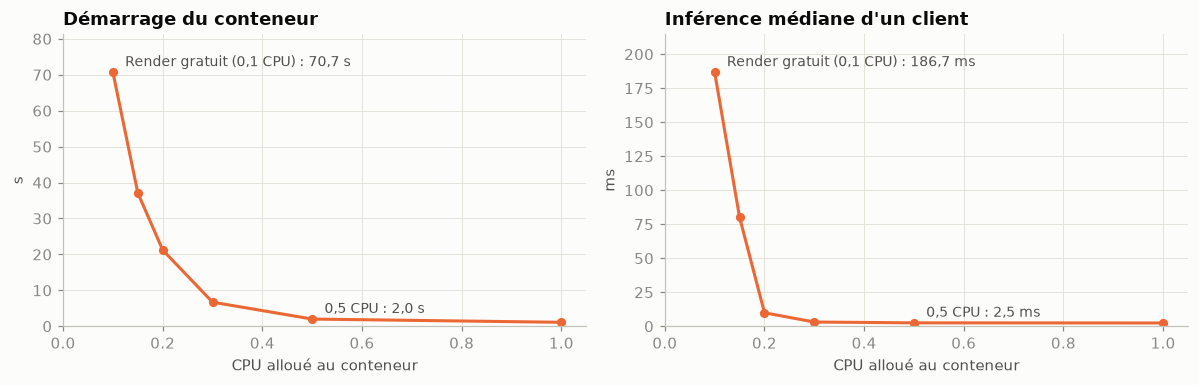

In [21]:
# Image optimisée, mesurée de 0,1 à 1 CPU (un essai par niveau)
paliers = pd.DataFrame(charger("mesure_docker_apres_paliers.json")["mesures"])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
graphiques = [("demarrage_s", "Démarrage du conteneur", "s"), ("inference_mediane_ms", "Inférence médiane d'un client", "ms")]
for ax, (colonne, titre, unite) in zip(axes, graphiques):
    ax.plot(paliers["cpus"], paliers[colonne], marker="o", markersize=5, color=COULEURS["Après"])
    # Valeur écrite seulement pour les deux configurations comparées dans le texte
    for x, texte in [(0.1, "Render gratuit (0,1 CPU)"), (0.5, "0,5 CPU")]:
        y = paliers.loc[paliers["cpus"] == x, colonne].iloc[0]
        ax.annotate(f"{texte} : {fr(y)} {unite}", (x, y), xytext=(8, 4), textcoords="offset points",
                    fontsize=9, color=ENCRE_SECONDAIRE)
    ax.set_xlim(0, 1.05)
    ax.set_ylim(0, paliers[colonne].max() * 1.15)  # marge pour le libellé du point le plus haut
    ax.set_xlabel("CPU alloué au conteneur")
    ax.set_ylabel(unite)
    ax.set_title(titre)
fig.tight_layout()
plt.show()

**Lecture : il y a un effet de seuil.**

- **À 0,1 CPU**, l'API met environ **une minute** à démarrer, et une prédiction prend environ **190 ms**.
- **À 0,5 CPU**, elle démarre en **2 s**, et une prédiction prend **2,5 ms**.
- **Au-delà de 0,5 CPU**, le gain devient faible.
- **Pourquoi un seuil ?**
  - Avec 0,1 CPU, Linux n'accorde au conteneur que 10 ms de calcul toutes les 100 ms, puis le met en pause.
  - Une prédiction qui demande un peu plus de 10 ms de calcul doit donc attendre la période suivante : d'où les « marches » de 100 ms observées sur Render.
  - Interrompu sans arrêt, le processus travaille aussi moins efficacement : les imports consomment 0,65 s de CPU à pleine puissance, mais près de 3 s à 0,1 CPU.
- **Conséquence sur Render.**
  - Sur l'offre gratuite, l'API s'endort après 15 minutes sans requête. Le premier client après une pause attend donc environ une minute.
  - Le démarrage, et pas seulement la latence, justifie de passer à **au moins 0,5 CPU** pour une vraie mise en production.

Ces mesures sont faites sur le Mac, alors que Render utilise des serveurs Linux de type amd64. Les ordres de grandeur concordent avec ce qu'on observe sur Render : un réveil d'environ une minute, et un calcul qui monte par marches de 100 ms.

### Ce qu'on n'a pas fait, et pourquoi

| Piste | Pourquoi elle n'est pas retenue |
|---|---|
| **Build en plusieurs étapes** (« multi-stage ») | Il sert à jeter les outils de compilation après l'installation. Ici, toutes les bibliothèques arrivent déjà compilées (« wheels ») : aucun outil de compilation n'est installé, donc il n'y a rien à jeter. Le gain serait nul. |
| **Image Alpine**, plus légère | Alpine utilise une autre bibliothèque C (musl) : les versions compilées de LightGBM ne fonctionnent pas dessus. Il faudrait tout recompiler, avec un risque d'écarts dans les scores. |
| **Retirer scikit-learn et pandas de l'image** | Gain possible : environ 80 Mo, et des imports nettement plus courts, puisque ces deux bibliothèques en représentent un peu plus de la moitié. Mais il faudrait réenregistrer le modèle dans un autre format : LightGBM natif, avec les médianes de l'imputation en numpy. La consigne est de garder exactement le même modèle. scipy, lui, reste indispensable à LightGBM. |

## 6. Configuration finale et justification

| Élément | Choix final | Justification |
|---|---|---|
| Code d'inférence | `imputer_rapide()` (numpy), puis LightGBM | Gain mesuré : plus de 4 fois en local, environ 13 fois sur le temps du modèle sur Render. Résultats identiques. |
| Modèle | `model.pkl` du Projet 6, inchangé (LightGBM, 200 arbres, `n_jobs=1`) | Consigne « même modèle ». Un seul fil de calcul (thread) : avec 0,1 CPU, plusieurs fils se disputeraient le même quota. |
| Bibliothèques | numpy 1.26.4, pandas 2.2.3, scikit-learn 1.5.2, lightgbm 4.6.0, versions figées | Mêmes versions qu'à l'entraînement : le modèle se recharge à l'identique. |
| Serveur | FastAPI et uvicorn, 1 processus, modèle chargé une seule fois au démarrage | Le calcul est limité par le processeur. Plusieurs processus sur 0,1 CPU se partageraient le même quota, et chacun chargerait le modèle en mémoire (512 Mo disponibles). |
| Image Docker | `python:3.12-slim` et `libgomp1`, utilisateur non-root, sans les suites de tests des bibliothèques, un seul fil de calcul (`OPENBLAS_NUM_THREADS=1`, `OMP_NUM_THREADS=1`) | Image de base minimale, et `libgomp1` est indispensable à LightGBM. 651 Mo au lieu de 796, 2 fils au lieu de 32, démarrage plus rapide d'environ 20 %, scores identiques (section 5). |
| Hébergement | Render, offre gratuite (0,1 CPU, 512 Mo), Francfort | Gratuit, déploiement de l'image Docker par la CI, même région que la base Neon. Suffisant pour la démonstration : p95 de 0,61 s avec 8 requêtes simultanées. |
| Matériel | Processeur (CPU), pas de carte graphique (GPU) | Un client par requête et 200 petits arbres : envoyer les données au GPU coûterait plus cher que le calcul lui-même. La **quantification** (réduire la précision des nombres) vise les réseaux de neurones, pas les arbres de décision. |

### Pour une vraie mise en production

- **Au moins 0,5 CPU.**
  - Mesuré en simulant les ressources avec Docker (section 5) : à 0,5 CPU, l'API démarre en 2 s au lieu d'environ une minute, et une prédiction prend 2,5 ms au lieu d'environ 190 ms.
  - Au-delà de 0,5 CPU, le gain devient faible.
  - Chez Render, cela correspond à une offre payante d'entrée de gamme.
- **Pas de mise en veille.** L'offre gratuite s'endort après 15 min sans requête et met près d'une minute à se réveiller, ce qui est incompatible avec du « quasi temps réel ». Une offre payante reste allumée.
- **Plusieurs instances si le volume augmente.** L'API ne garde aucune information entre deux requêtes (tout est en base) : on peut lancer plusieurs copies derrière un **répartiteur de charge**, qui distribue les requêtes entre elles.

## 7. Pistes d'amélioration et points de vigilance

### Où chercher le prochain gain ?

Après optimisation, le temps se répartit autrement. La **loi d'Amdahl** donne le gain maximal qu'on peut espérer en optimisant une étape. Même si cette étape devenait instantanée, la prédiction prendrait encore le temps des autres étapes.

In [22]:
total_apres = etapes_apres["médiane (ms)"].sum()
amdahl = pd.DataFrame({
    "temps actuel (ms)": etapes_apres["médiane (ms)"],
    "part du temps (%)": etapes_apres["médiane (ms)"] / total_apres * 100,
    "gain maximal sur la prédiction (fois)": total_apres / (total_apres - etapes_apres["médiane (ms)"]),
})
amdahl.round(2)

,temps actuel (ms),part du temps (%),gain maximal sur la prédiction (fois)
1. Préparation,1.13,45.38,1.83
2. Imputation,0.76,30.47,1.44
3. LightGBM,0.60,24.15,1.32


**Lecture.** La préparation du tableau est maintenant l'étape la plus longue. La rendre instantanée rendrait la prédiction au mieux environ 1,8 fois plus rapide. Pour LightGBM, et donc pour ONNX Runtime, le gain maximal n'est que d'environ 1,3 fois.

### Pistes classées

| Piste | Gain attendu | Effort |
|---|---|---|
| **Préparation en numpy** : construire la matrice directement depuis les données reçues, sans `pd.DataFrame` | Jusqu'à environ 1,8 fois sur la prédiction | Faible : quelques lignes, à vérifier avec le même test d'équivalence |
| **Écriture en base après l'envoi de la réponse** (tâche de fond) | Le client n'attend plus l'écriture dans Neon. Cette durée n'est pas stockée en base : elle apparaît dans les logs Render (`ecriture_bdd_ms`). | Faible |
| **Retirer scikit-learn et pandas de l'image** (modèle réenregistré au format natif de LightGBM) | Environ 80 Mo de moins et des imports nettement plus courts (section 5) | Élevé : nouveau format du modèle, à valider au regard de la consigne « même modèle » |
| **ONNX Runtime** pour LightGBM | Au mieux environ 1,3 fois (loi d'Amdahl) | Moyen : nouvelle dépendance, conversion, vérification des scores |
| **Réutiliser les connexions** côté applications clientes (HTTP keep-alive) | Évite de renégocier une connexion sécurisée à chaque requête | Côté applications de Crédit Express |
| **Point d'entrée par lot** (`/predict_batch`) | Environ 0,03 ms par client au lieu de 2,7 ms pour les traitements de masse | Moyen |

### Points de vigilance

- **Les mesures varient.**
  - En local, de quelques pourcents d'une exécution à l'autre : le Mac fait autre chose en même temps.
  - Sur l'offre gratuite de Render, d'un jour à l'autre : la machine est partagée.
  - Ce sont les ordres de grandeur qui comptent.
- **`imputer_rapide()` dépend de la structure interne de l'imputer du Projet 6** (`external_cols_`, `_group_key`…). Si le modèle est réentraîné avec une autre imputation, il faudra adapter cette fonction. Le test d'équivalence de la CI le signalera immédiatement.
- **Le monitoring continue** : la colonne `version` de la base permet de comparer chaque nouvelle version à la précédente, exactement comme dans ce rapport.

### Comment relancer ce rapport

1. Installez les dépendances : `pip install -r requirements-analyse.txt`.
2. Vérifiez la présence de ces fichiers :
   - `.env`, qui contient `DATABASE_URL` ;
   - `data/prepared_dataset.parquet` ;
   - les bilans de simulation `data/simulation_vagues.json` et `data/mesure_render_2fb5352.json`.
3. Exécutez toutes les cellules (environ 1 min 15), ou en ligne de commande : `jupyter nbconvert --to notebook --execute --inplace notebooks/03_optimisation_performances.ipynb`.
4. Pour la seule mesure locale, sans base de données : `python -m scripts.mesure_inference`.
5. Pour la section 5 : Docker doit être lancé. Construisez les deux images (`docker build -t scoring-api:apres .`), puis lancez `scripts/mesure_docker.py` avec les commandes indiquées en tête du script. Les bilans sont écrits dans `data/mesure_docker_*.json`.